# Student Dropout Risk 2026

Dataset: https://www.kaggle.com/ (Student Dropout Risk 2026 - paste the exact dataset link here)

Main question of this research: How does class attendance affect academic performance (GPA in semester 2)?

Additional question: do students who drop out attend fewer classes than those who stay?

In [1]:
# Import Python Libraries
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

%matplotlib inline

In [2]:
data_path = 'input/student_dropout_risk_2026.csv'
df = pd.read_csv(data_path)

df.head()

,person_id,age,gender,nationality,first_generation,disability_status,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,...,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
0,1,23,Male,Brazil,0,0,Low,1,0,1,...,4,16.3,0,3,8,0,6,37,5.7,0
1,2,18,Other,USA,1,1,High,1,1,0,...,3,8.4,1,1,7,0,6,15,5.4,1
2,3,24,Other,USA,0,0,High,0,1,1,...,3,11.3,1,0,2,0,3,4,4.3,0
3,4,25,Female,USA,0,1,Middle,1,1,0,...,2,13.2,1,1,5,0,7,10,6.7,0
4,5,15,Female,Canada,0,0,Low,1,1,0,...,4,7.4,1,0,7,0,10,24,5.8,0


In [3]:
df.tail(10)

,person_id,age,gender,nationality,first_generation,disability_status,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,...,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
99990,99991,20,Female,China,0,0,Low,1,1,0,...,3,4.4,1,0,9,0,6,20,8.2,0
99991,99992,15,Female,China,1,0,High,0,1,0,...,2,1.2,0,3,8,0,7,0,6.5,1
99992,99993,16,Female,India,0,0,High,0,1,1,...,4,17.0,1,6,4,0,5,27,5.6,0
99993,99994,20,Male,USA,0,0,High,1,1,0,...,5,18.3,1,0,6,0,5,64,7.0,0
99994,99995,19,Female,Mexico,0,1,Low,1,0,0,...,1,2.1,0,4,8,0,7,25,5.4,1
99995,99996,25,Female,USA,0,0,Middle,1,1,1,...,10,6.2,0,0,4,0,6,11,5.9,0
99996,99997,24,Female,India,0,1,Middle,0,1,1,...,0,8.7,1,3,7,1,5,21,5.5,1
99997,99998,27,Female,USA,0,0,Middle,1,1,1,...,8,7.5,0,2,2,0,6,29,5.8,0
99998,99999,21,Male,UK,0,0,High,0,1,0,...,6,13.6,1,2,4,1,10,43,6.2,0
99999,100000,24,Male,Philippines,0,0,Low,0,1,0,...,5,8.7,1,0,7,1,9,14,6.9,0


In [4]:
df.dtypes

person_id                         int64
age                               int64
gender                           object
nationality                      object
first_generation                  int64
disability_status                 int64
family_income_level              object
scholarship_holder                int64
tuition_up_to_date                int64
part_time_job                     int64
weekly_work_hours                 int64
course_type                      object
study_mode                       object
semester                          int64
international_student             int64
admission_grade                 float64
previous_qualification_grade    float64
units_enrolled                    int64
units_passed                      int64
units_failed                      int64
gpa_semester_1                  float64
gpa_semester_2                  float64
attendance_rate                 float64
assignments_submitted_rate      float64
library_visits_per_month          int64


In [5]:
df.describe()

,person_id,age,first_generation,disability_status,scholarship_holder,tuition_up_to_date,part_time_job,weekly_work_hours,semester,international_student,...,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,50000.500000,21.520840,0.420130,0.208770,0.589700,0.784860,0.481920,8.744620,3.617970,0.18094,...,4.366800,7.272294,0.594790,2.372140,6.448120,0.315560,6.318820,23.261360,6.556512,0.320040
std,28867.657797,3.399468,0.493582,0.406432,0.491891,0.410921,0.499676,10.232842,2.112763,0.38497,...,3.651653,3.936264,0.490935,2.587122,2.154185,0.464741,2.079066,23.932468,1.204067,0.466494
min,1.000000,15.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.00000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,4.000000,0.000000
25%,25000.750000,19.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,2.000000,0.00000,...,2.000000,4.500000,0.000000,0.000000,5.000000,0.000000,5.000000,6.000000,5.700000,0.000000
50%,50000.500000,21.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,3.000000,0.00000,...,3.000000,7.100000,1.000000,2.000000,7.000000,0.000000,6.000000,16.000000,6.500000,0.000000
75%,75000.250000,24.000000,1.000000,0.000000,1.000000,1.000000,1.000000,18.000000,5.000000,0.00000,...,6.000000,9.800000,1.000000,3.000000,8.000000,1.000000,8.000000,33.000000,7.400000,1.000000
max,100000.000000,30.000000,1.000000,1.000000,1.000000,1.000000,1.000000,40.000000,8.000000,1.00000,...,30.000000,29.600000,1.000000,20.000000,10.000000,1.000000,10.000000,120.000000,10.000000,1.000000


In [6]:
df['dropout'].value_counts()

dropout
0    67996
1    32004
Name: count, dtype: int64

In [7]:
len(df['attendance_rate'].unique())

889

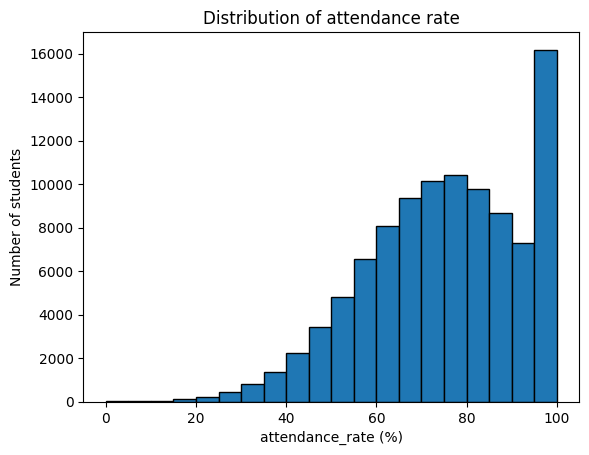

In [8]:
plt.hist(df["attendance_rate"], bins=20, edgecolor='black')
plt.xlabel('attendance_rate (%)')
plt.ylabel('Number of students')
plt.title('Distribution of attendance rate')
plt.show()

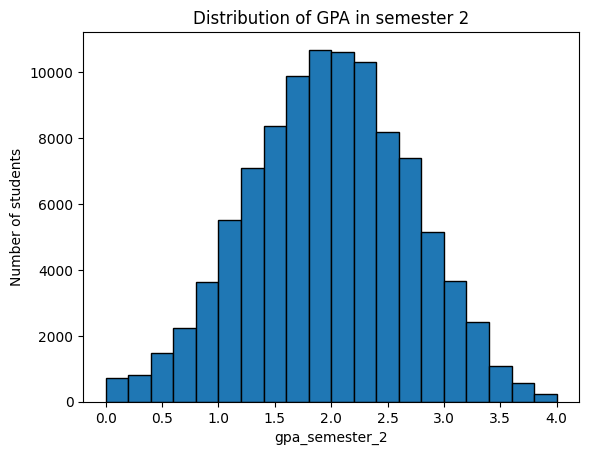

In [9]:
plt.hist(df["gpa_semester_2"], bins=20, edgecolor='black')
plt.xlabel('gpa_semester_2')
plt.ylabel('Number of students')
plt.title('Distribution of GPA in semester 2')
plt.show()

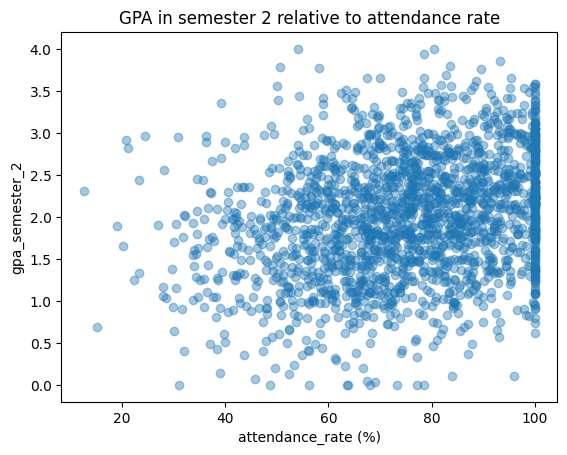

In [10]:
# The dataset has 100,000 rows, so we plot a random sample of 2,000 students
# to keep the scatter plot readable
sample = df.sample(2000, random_state=42)

attendance = sample["attendance_rate"]
gpa_2 = sample["gpa_semester_2"]

plt.scatter(attendance, gpa_2, alpha=0.4)
plt.xlabel('attendance_rate (%)')
plt.ylabel('gpa_semester_2')
plt.title('GPA in semester 2 relative to attendance rate')
plt.show()

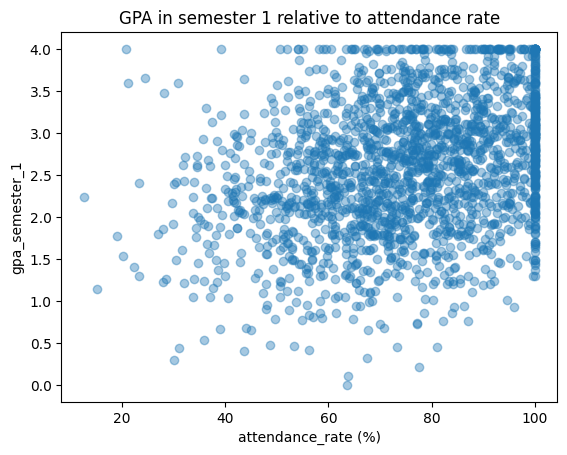

In [11]:
gpa_1 = sample["gpa_semester_1"]

plt.scatter(attendance, gpa_1, alpha=0.4)
plt.xlabel('attendance_rate (%)')
plt.ylabel('gpa_semester_1')
plt.title('GPA in semester 1 relative to attendance rate')
plt.show()

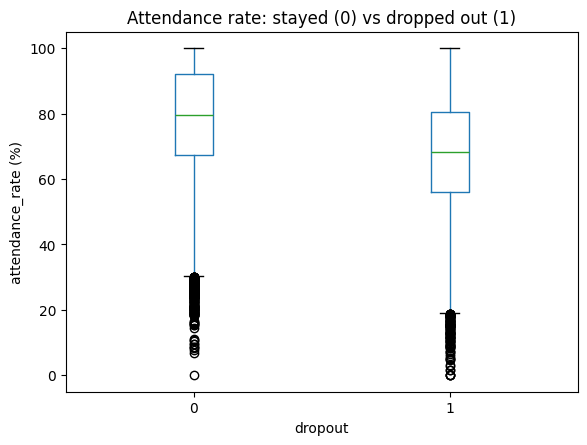

In [12]:
df.boxplot(by='dropout', column=['attendance_rate'], grid=False)
plt.suptitle('')
plt.title('Attendance rate: stayed (0) vs dropped out (1)')
plt.ylabel('attendance_rate (%)')
plt.show()

In [13]:
missing_data = df.isnull().sum()
print(missing_data)

person_id                       0
age                             0
gender                          0
nationality                     0
first_generation                0
disability_status               0
family_income_level             0
scholarship_holder              0
tuition_up_to_date              0
part_time_job                   0
weekly_work_hours               0
course_type                     0
study_mode                      0
semester                        0
international_student           0
admission_grade                 0
previous_qualification_grade    0
units_enrolled                  0
units_passed                    0
units_failed                    0
gpa_semester_1                  0
gpa_semester_2                  0
attendance_rate                 0
assignments_submitted_rate      0
library_visits_per_month        0
lms_logins_per_week             0
extracurricular_activities      0
missed_deadlines                0
stress_level                    0
mental_health_

In [14]:
from sklearn.linear_model import LinearRegression
lm = LinearRegression()
lm
#Not fitted

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


Parameters of fit():

X: {array-like, sparse matrix} of shape (n_samples, n_features). Training data.

y: array-like of shape (n_samples,) or (n_samples, n_targets). Target values.

In [15]:
X_train = df[['attendance_rate']]
Y_train = df['gpa_semester_2']
lm.fit(X_train, Y_train)
#Fitted

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [16]:
#Create new data, e.g. 90% attendance
new_data = pd.DataFrame({'attendance_rate': [90]})

#Predicting GPA in semester 2 for 90% attendance
predicted_gpa = lm.predict(new_data)

#Printing
print(f"Predicted GPA in semester 2: {predicted_gpa[0]:.2f}")

Predicted GPA in semester 2: 2.12


The value of b0, also called the intercept, shows the point where the estimated regression line crosses the y axis. It is the value of the estimated response f(x) for x = 0. The value of b1 determines the slope of the estimated regression line.

In [17]:
lm.intercept_

np.float64(1.292926641999406)

coef_ is an array of shape (n_features,) with the estimated coefficients of the linear regression problem. It would be a 2D array of shape (n_targets, n_features) if multiple targets are passed during fit.

In [18]:
lm.coef_

array([0.0091591])

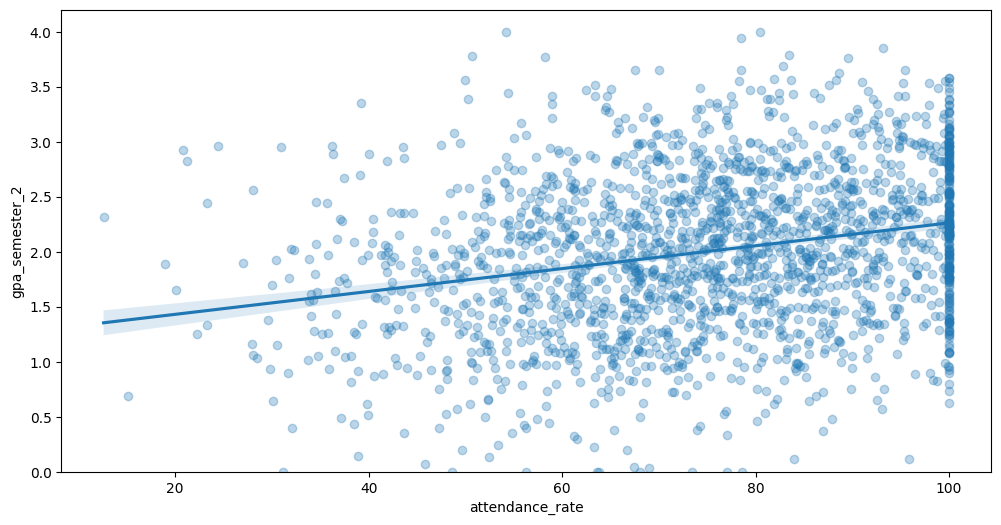

In [19]:
width = 12
height = 6
plt.figure(figsize=(width, height))
sns.regplot(x="attendance_rate", y="gpa_semester_2", data=sample,
            scatter_kws={'alpha': 0.3})
plt.ylim(0,)
plt.show()

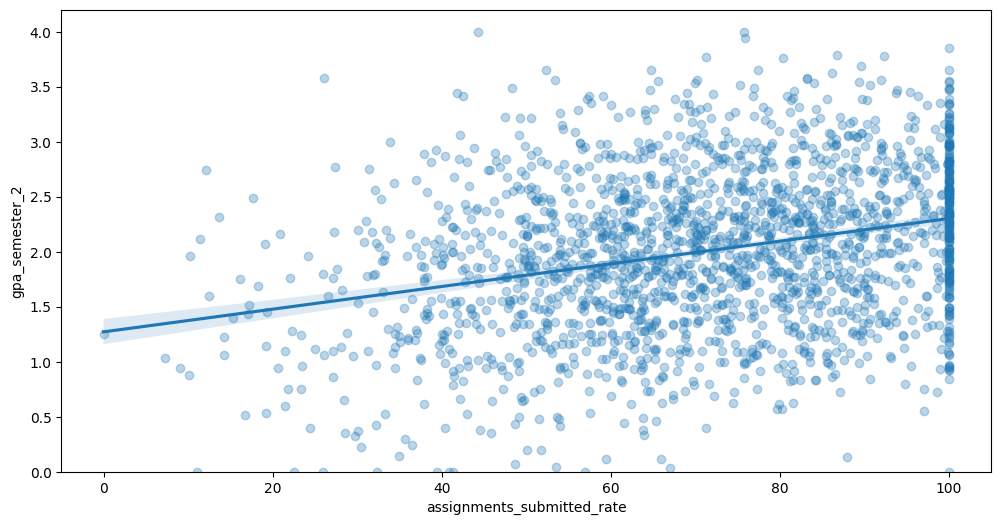

In [20]:
plt.figure(figsize=(width, height))
sns.regplot(x="assignments_submitted_rate", y="gpa_semester_2", data=sample,
            scatter_kws={'alpha': 0.3})
plt.ylim(0,)
plt.show()